In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/clean/escenarios_deportivos_limpio.csv")
urbano = df[df["zona"] == "Urbana"]

cols_inst = ["grama_natural", "sintetica", "multiple", "baloncesto", "voleibol",
             "piscina_adultos", "piscina_ninos", "juegos_infantiles", "biosaludables",
             "pista_patinaje", "pista_de_trote", "pista_bmx", "tenis", "tejo",
             "hockey", "microfutb", "voley_playa"]

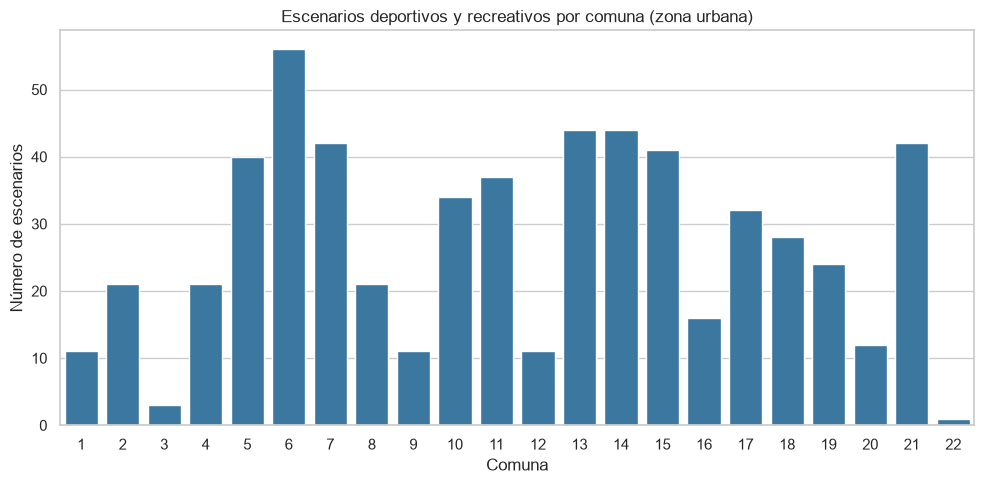

In [2]:
conteo = urbano["comuna"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=conteo.index, y=conteo.values, color="#2a7ab0", ax=ax)
ax.set_title("Escenarios deportivos y recreativos por comuna (zona urbana)")
ax.set_xlabel("Comuna")
ax.set_ylabel("Número de escenarios")
plt.tight_layout()
plt.savefig("../reports/figures/escenarios_por_comuna.png", dpi=150)
plt.show()

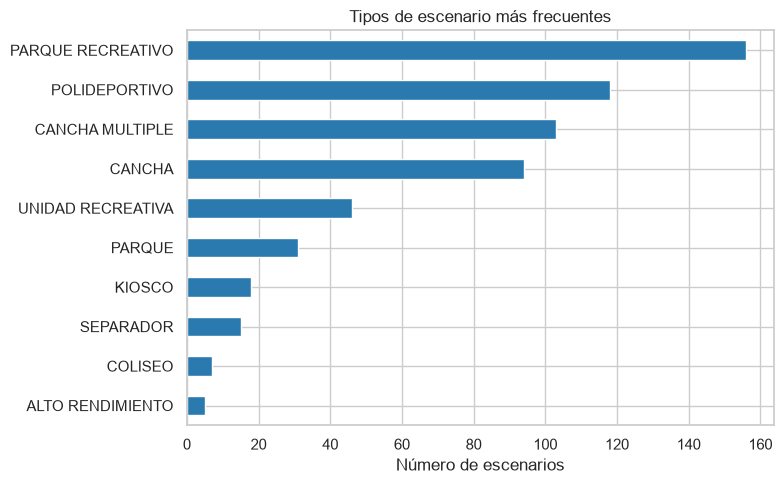

In [3]:
top_tipos = df["tipo_escenario"].value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
top_tipos.plot.barh(color="#2a7ab0", ax=ax)
ax.set_title("Tipos de escenario más frecuentes")
ax.set_xlabel("Número de escenarios")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../reports/figures/tipos_escenario.png", dpi=150)
plt.show()

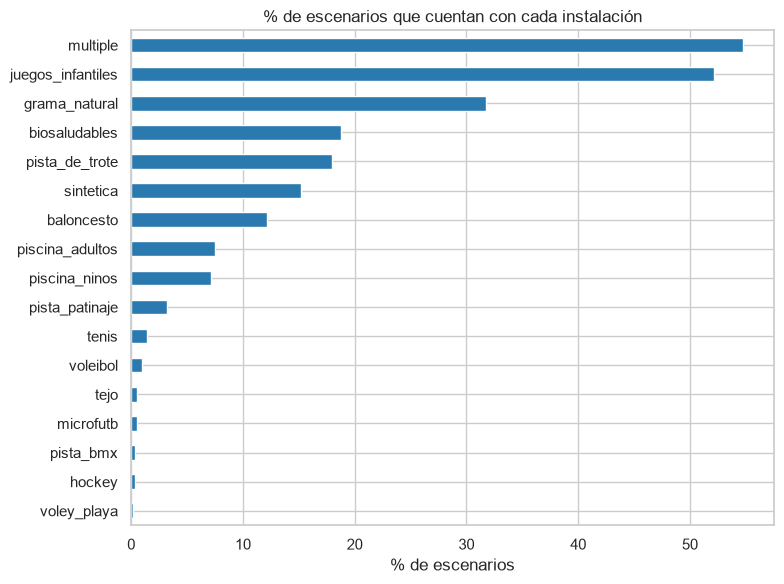

In [4]:
pct = ((df[cols_inst] > 0).mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
pct.plot.barh(color="#2a7ab0", ax=ax)
ax.set_title("% de escenarios que cuentan con cada instalación")
ax.set_xlabel("% de escenarios")
plt.tight_layout()
plt.savefig("../reports/figures/instalaciones_pct.png", dpi=150)
plt.show()

In [5]:
df.groupby("zona").agg(
    escenarios=("escenario", "count"),
    comunas_o_corregimientos=("comuna", "nunique"),
    promedio_instalaciones=("total_instalaciones", "mean"),
    promedio_tipos=("tipos_instalacion", "mean"),
).round(2)

,escenarios,comunas_o_corregimientos,promedio_instalaciones,promedio_tipos
zona,,,,
Rural,25,15,0.92,0.92
Urbana,592,22,2.42,2.31
